
# 07 — PCA Experiments

## 07.1 — Explained Variance and Dimensionality

We first review the training-only PCA analysis from Notebook 02.

The aim is to understand how much numerical information is retained as the number of principal components increases.

This analysis is descriptive. Whether PCA improves default classification will be established through controlled validation experiments.


Source: d:\ML_Projects\P2P-Lending-Default-Prediction\reports\preprocessing\02_pca_explained_variance.csv
Components analyzed: 51


,variance_target,components,features_reduced,reduction_pct
0,90%,27,24,47.06
1,95%,32,19,37.25
2,99%,41,10,19.61


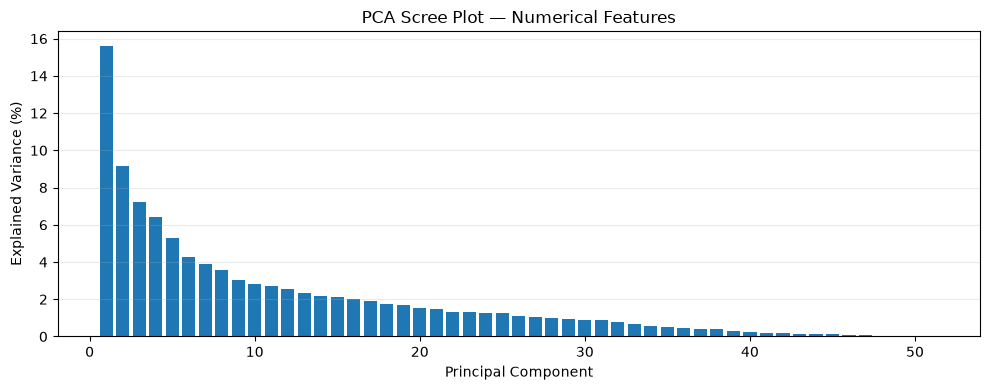

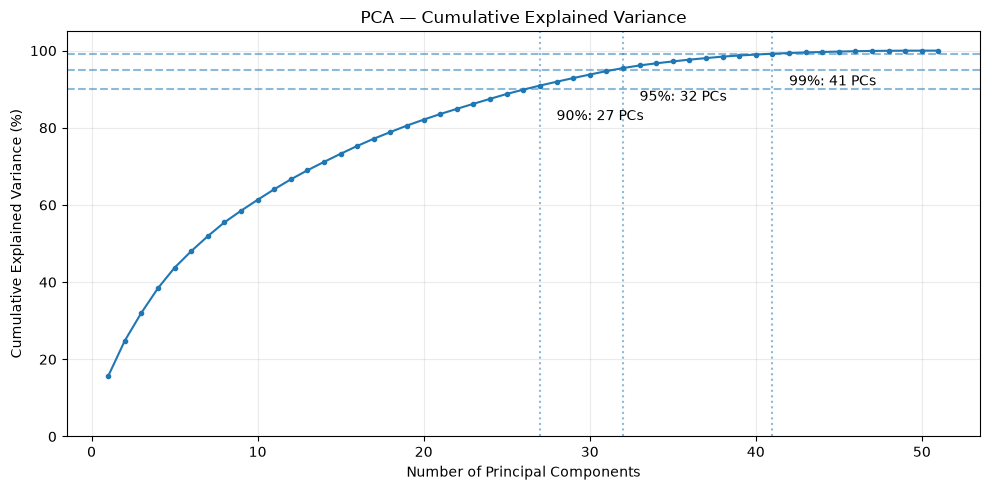

PCA variance analysis complete.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

PCA_REPORT = (
    ROOT / "reports/preprocessing/02_pca_explained_variance.csv"
)

# Locate the report if the existing notebook used
# a different output subfolder.
if not PCA_REPORT.exists():
    matches = list(
        (ROOT / "reports").rglob("02_pca_explained_variance.csv")
    )
    assert len(matches) == 1, (
        f"Expected one PCA report, found {len(matches)}"
    )
    PCA_REPORT = matches[0]

pca_df = pd.read_csv(PCA_REPORT)

required = {"component", "explained_pct", "cumulative_pct"}
assert required.issubset(pca_df.columns)

print("Source:", PCA_REPORT)
print("Components analyzed:", len(pca_df))

# Number of components required for each target
summary = []

for variance in [90, 95, 99]:
    eligible = pca_df[
        pca_df["cumulative_pct"] >= variance
    ]

    n_components = int(eligible["component"].iloc[0])

    summary.append({
        "variance_target": f"{variance}%",
        "components": n_components,
        "features_reduced": len(pca_df) - n_components,
        "reduction_pct": round(
            100 * (1 - n_components / len(pca_df)), 2
        ),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

# Scree plot: variance explained by each component
plt.figure(figsize=(10, 4))

plt.bar(
    pca_df["component"],
    pca_df["explained_pct"]
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot — Numerical Features")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    pca_df["component"],
    pca_df["cumulative_pct"],
    marker=".",
)

for target in [90, 95, 99]:
    count = summary_df.loc[
        summary_df["variance_target"] == f"{target}%",
        "components",
    ].iloc[0]

    plt.axhline(target, linestyle="--", alpha=0.5)
    plt.axvline(count, linestyle=":", alpha=0.5)

    plt.annotate(
        f"{target}%: {count} PCs",
        xy=(count, target),
        xytext=(count + 1, target - 8),
    )

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA — Cumulative Explained Variance")
plt.ylim(0, 105)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("PCA variance analysis complete.")



## 07.2 — PCA Model Comparison: Data Preparation

We compare Logistic Regression with and without PCA using identical observations and model settings.

The saved model's feature-engineering and preprocessing stages are reused to obtain consistently cleaned features. Numerical variables are standardized using training data only.

Missingness indicators and one-hot categorical variables remain outside PCA. The 2016 test set is not used.


In [2]:

# 07.2 — Prepare common training and validation matrices

import sys
import gc
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import polars as pl

from scipy import sparse
from sklearn.preprocessing import StandardScaler
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from loanrisk.predict import load_model

SOURCE = ROOT / "data/interim/lendingclub_2013_2016_36m_raw.parquet"

REPORT_DIR = ROOT / "reports/pca_experiments"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

bundle = load_model()
pipeline = bundle["pipeline"]
raw_features = list(bundle["raw_columns"])

# Frozen chronological splits
lf = pl.scan_parquet(SOURCE)

train_lf = lf.filter(
    (pl.col("issue_date") >= date(2013, 1, 1))
    & (pl.col("issue_date") < date(2015, 10, 1))
)

val_lf = lf.filter(
    (pl.col("issue_date") >= date(2015, 10, 1))
    & (pl.col("issue_date") < date(2016, 1, 1))
)

def load_split(data):
    frame = (
        data.select(raw_features + ["target"])
        .collect()
        .to_pandas()
    )

    X = frame[raw_features]
    y = frame["target"].astype(int).to_numpy()

    return X, y

X_train_raw, y_train = load_split(train_lf)
X_val_raw, y_val = load_split(val_lf)

assert len(X_train_raw) == 457355
assert len(X_val_raw) == 88810

# Reuse the fitted transformation stages,
# excluding the XGBoost model.
transformer = pipeline[:-1]

def transform_to_float32(X):
    output = transformer.transform(X)

    if sparse.issparse(output):
        output = output.toarray()

    return np.asarray(output, dtype=np.float32)

Z_train = transform_to_float32(X_train_raw)
Z_val = transform_to_float32(X_val_raw)

# Find numerical output columns automatically
preprocessor = pipeline.steps[-2][1]

numeric_slice = preprocessor.output_indices_["numeric"]

other_columns = np.r_[
    np.arange(0, numeric_slice.start),
    np.arange(numeric_slice.stop, Z_train.shape[1]),
]

# Numerical features
X_num_train = Z_train[:, numeric_slice]
X_num_val = Z_val[:, numeric_slice]

# Categorical and indicator features — never PCA-transform
X_other_train = Z_train[:, other_columns].copy()
X_other_val = Z_val[:, other_columns].copy()

# Standardize numerical variables, fitted on training only
scaler = StandardScaler()

X_num_train = scaler.fit_transform(
    X_num_train
).astype(np.float32)

X_num_val = scaler.transform(
    X_num_val
).astype(np.float32)

assert np.isfinite(X_num_train).all()
assert np.isfinite(X_num_val).all()

print("TRAIN / VALIDATION")
print("Train:", len(y_train))
print("Validation:", len(y_val))

print("\nFEATURE DIMENSIONS")
print("Numerical:", X_num_train.shape[1])
print("Other encoded features:", X_other_train.shape[1])
print("Total:", Z_train.shape[1])

print("\nData preparation complete.")
print("Numerical scaling fitted on training only.")

# Release larger intermediate objects
del Z_train, Z_val, X_train_raw, X_val_raw
gc.collect()


TRAIN / VALIDATION
Train: 457355
Validation: 88810

FEATURE DIMENSIONS
Numerical: 55
Other encoded features: 67
Total: 122

Data preparation complete.
Numerical scaling fitted on training only.


222

In [3]:

# 07.3 — Logistic Regression vs PCA

import time
import gc

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
)

# Fit PCA on training numerical features only
pca_start = time.perf_counter()

pca = PCA(svd_solver="full")
pca.fit(X_num_train)

cumulative = np.cumsum(
    pca.explained_variance_ratio_
)

component_counts = {
    target: int(np.searchsorted(cumulative, target) + 1)
    for target in [0.90, 0.95, 0.99]
}

print("PCA fitting time:",
      round(time.perf_counter() - pca_start, 1), "seconds")

print("\nComponents required:")
for target, count in component_counts.items():
    print(f"{target:.0%} variance: {count} components")

# Transform once, then use different numbers of PCs
X_pca_train = pca.transform(X_num_train).astype(np.float32)
X_pca_val = pca.transform(X_num_val).astype(np.float32)

def evaluate_lr(name, train_num, val_num):
    X_train_model = np.hstack([
        train_num,
        X_other_train
    ])

    X_val_model = np.hstack([
        val_num,
        X_other_val
    ])

    model = LogisticRegression(
        class_weight="balanced",
        solver="lbfgs",
        max_iter=400,
        random_state=42,
    )

    start = time.perf_counter()
    model.fit(X_train_model, y_train)
    fit_seconds = time.perf_counter() - start

    probabilities = model.predict_proba(X_val_model)[:, 1]
    predicted = (probabilities >= 0.50).astype(int)

    result = {
        "experiment": name,
        "features": X_train_model.shape[1],
        "pr_auc": average_precision_score(
            y_val, probabilities
        ),
        "roc_auc": roc_auc_score(
            y_val, probabilities
        ),
        "f1": f1_score(y_val, predicted),
        "precision": precision_score(
            y_val, predicted, zero_division=0
        ),
        "recall": recall_score(
            y_val, predicted, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predicted
        ),
        "fit_seconds": fit_seconds,
    }

    del X_train_model, X_val_model, model
    gc.collect()

    return result

results = []

# A — Logistic Regression without PCA
print("\nTraining A: Logistic Regression (No PCA)")
results.append(
    evaluate_lr(
        "A - No PCA",
        X_num_train,
        X_num_val,
    )
)

# B, C, D — Logistic Regression with PCA
for target, count in component_counts.items():
    name = f"PCA {int(target * 100)}%"

    print(f"\nTraining {name}: {count} components")

    results.append(
        evaluate_lr(
            name,
            X_pca_train[:, :count],
            X_pca_val[:, :count],
        )
    )

comparison = pd.DataFrame(results)

print("\nVALIDATION PERFORMANCE")
display(comparison.round(5))

# Compare against non-PCA logistic regression
baseline_ap = comparison.loc[0, "pr_auc"]
baseline_roc = comparison.loc[0, "roc_auc"]

comparison["pr_auc_change"] = (
    comparison["pr_auc"] - baseline_ap
)

comparison["roc_auc_change"] = (
    comparison["roc_auc"] - baseline_roc
)

print("\nCHANGE RELATIVE TO NO PCA")
display(
    comparison[
        [
            "experiment",
            "features",
            "pr_auc",
            "pr_auc_change",
            "roc_auc",
            "roc_auc_change",
            "f1",
            "fit_seconds",
        ]
    ].round(5)
)

comparison.to_csv(
    REPORT_DIR / "07_pca_model_comparison.csv",
    index=False
)

print("\nPCA model comparison complete.")
print("Saved original model remains unchanged.")


PCA fitting time: 0.6 seconds

Components required:
90% variance: 30 components
95% variance: 36 components
99% variance: 46 components

Training A: Logistic Regression (No PCA)

Training PCA 90%: 30 components

Training PCA 95%: 36 components

Training PCA 99%: 46 components

VALIDATION PERFORMANCE


,experiment,features,pr_auc,roc_auc,f1,precision,recall,balanced_accuracy,fit_seconds
0,A - No PCA,122,0.28666,0.70607,0.35438,0.25079,0.60381,0.64468,2.86844
1,PCA 90%,97,0.28226,0.70223,0.35125,0.24819,0.60070,0.64175,2.48374
2,PCA 95%,103,0.28416,0.70360,0.35270,0.24986,0.59941,0.64286,2.93292
3,PCA 99%,113,0.28564,0.70540,0.35449,0.25040,0.60669,0.64505,3.18561



CHANGE RELATIVE TO NO PCA


,experiment,features,pr_auc,pr_auc_change,roc_auc,roc_auc_change,f1,fit_seconds
0,A - No PCA,122,0.28666,0.00000,0.70607,0.00000,0.35438,2.86844
1,PCA 90%,97,0.28226,-0.00440,0.70223,-0.00385,0.35125,2.48374
2,PCA 95%,103,0.28416,-0.00251,0.70360,-0.00247,0.35270,2.93292
3,PCA 99%,113,0.28564,-0.00102,0.70540,-0.00068,0.35449,3.18561



PCA model comparison complete.
Saved original model remains unchanged.


### Conclusion — PCA Analysis

PCA-based dimensionality reduction provided no meaningful improvement in Logistic Regression performance. The original model achieved a PR-AUC of 0.28666, while PCA variants achieved slightly lower scores (0.28226–0.28564). Although PCA reduced the number of features, the predictive performance remained similar or declined slightly.

Furthermore, PCA may reduce interpretability and potentially affect tree-based models such as XGBoost, which can learn nonlinear relationships and feature interactions directly. However, its effect on tree-based models was not experimentally evaluated.

**Final Decision:** We retain the complete feature set without PCA, as dimensionality reduction offered no significant predictive benefit and preserving the original features supports model interpretability.